# MWIS Experiment Comparison

This notebook compares the five four-minute MWIS scenarios from Experiments 1–3 and the three QPU-size profiles from Experiment 4. It reports pipeline and LP-refined bounds separately. Run it from the project root or the `results` folder; outputs go to `results/runs/mwis/experiment_comparison/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

# Find the results folder from either supported working directory.
HERE = Path.cwd()
RESULTS_DIR = HERE if (HERE / "_config.json").exists() else HERE / "results"
OUTPUT_DIR = RESULTS_DIR / "runs" / "mwis" / "experiment_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SCENARIOS = [
    {"run": "exp1_s100_g50", "label": "Baseline 100/50", "satellites": 100, "gateways": 50},
    {"run": "exp2_s200_g50", "label": "Satellites 200/50", "satellites": 200, "gateways": 50},
    {"run": "exp2_s500_g50", "label": "Satellites 500/50", "satellites": 500, "gateways": 50},
    {"run": "exp3_s500_g25", "label": "Gateways 500/25", "satellites": 500, "gateways": 25},
    {"run": "exp3_s500_g100", "label": "Gateways 500/100", "satellites": 500, "gateways": 100},
]

if not (RESULTS_DIR / "runs" / "mwis" / "pipeline_results").is_dir():
    raise FileNotFoundError("Run this notebook from the project root or results folder.")


In [2]:
def read_metrics(path):
    frame = pd.read_csv(path)
    return dict(zip(frame["metric"], frame["value"]))


def load_scenario(spec):
    mwis_dir = RESULTS_DIR / "runs" / "mwis" / "pipeline_results" / spec["run"]
    qubo_dir = RESULTS_DIR / "runs" / "mwis" / "qubo_annealing" / spec["run"]
    mwis_config = json.loads((mwis_dir / "run_config_log.json").read_text(encoding="utf-8"))
    qubo_config = json.loads((qubo_dir / "run_config_log.json").read_text(encoding="utf-8"))
    expected_input = f"data/experiment_inputs/exp1_3_snapshot_2026-09-27/scenario_inputs/slots_s{spec['satellites']}_g{spec['gateways']}.csv"

    if mwis_config["candidate_slot_csv"] != expected_input or qubo_config["candidate_slot_csv"] != expected_input:
        raise ValueError(f"Unexpected input file for {spec['run']}.")
    if qubo_config["qubo_input_run"] != f"runs/mwis/pipeline_results/{spec['run']}":
        raise ValueError(f"QUBO run does not match MWIS run for {spec['run']}.")

    mwis = read_metrics(mwis_dir / "final_summary.csv")
    reconstructed = read_metrics(qubo_dir / "reconstructed_summary.csv")
    terminals = pd.read_csv(qubo_dir / "terminal_qubo_summary.csv")
    decomposition = pd.read_csv(mwis_dir / "decomposition_summary.csv")
    root_type = dict(zip(decomposition["component_id"], decomposition["root_type"]))
    terminals["provenance"] = terminals["original_component_id"].map(root_type)

    direct_terminals = int((terminals["provenance"] == "terminal").sum())
    separator_terminals = int((terminals["provenance"] == "separator").sum())
    if direct_terminals != int(float(mwis["Subgraphs solved directly"])):
        raise ValueError(f"Direct-terminal count differs for {spec['run']}.")
    if separator_terminals != int(float(mwis["Subgraphs solved exactly with separator decomposition"])):
        raise ValueError(f"Separator-terminal count differs for {spec['run']}.")

    return {
        **spec,
        "mwis_dir": mwis_dir,
        "qubo_dir": qubo_dir,
        "mwis": mwis,
        "reconstructed": reconstructed,
        "terminals": terminals,
        "nodes": pd.read_csv(mwis_dir / "conflict_graph_nodes.csv"),
        "edges": pd.read_csv(mwis_dir / "conflict_graph_edges.csv"),
        "direct_terminals": direct_terminals,
        "separator_terminals": separator_terminals,
        "qpu_node_limit": int(mwis_config["max_qpu_terminal_nodes"]),
        "qpu_coupler_limit": int(mwis_config["max_qpu_terminal_couplers"]),
    }


RUN_DATA = [load_scenario(spec) for spec in SCENARIOS]


In [3]:
def lp_refined_bound(data):
    reconstructed = data["reconstructed"]
    feasible = float(reconstructed["Total feasible objective"])
    pipeline_bound = float(reconstructed["MWIS producer conservative objective upper bound"])
    if int(float(data["mwis"]["Components with incomplete separator decomposition"])) == 0:
        return None, "not applicable (all components exact)"
    lp_path = data["mwis_dir"] / "lp_bound_analysis.json"
    if not lp_path.exists():
        return None, "not run"

    lp = json.loads(lp_path.read_text(encoding="utf-8"))
    expected_input = f"data/experiment_inputs/exp1_3_snapshot_2026-09-27/scenario_inputs/slots_s{data['satellites']}_g{data['gateways']}.csv"
    lp_input = lp.get("input", lp.get("input_candidate_csv"))
    lp_data = lp.get("lp_refinement", lp.get("comparison", lp))
    refined = lp_data.get("refined_global_upper_bound")
    if lp_input != expected_input or refined is None:
        raise ValueError(f"LP bound report does not match {data['run']}.")
    refined = float(refined)
    if refined < feasible - 1e-6 or refined > pipeline_bound + 1e-6:
        raise ValueError(f"Invalid refined bound for {data['run']}.")
    status = "LP-tightened" if refined < pipeline_bound - 1e-6 else "LP applied; no tighter bound"
    return refined, status


records = []
for data in RUN_DATA:
    mwis = data["mwis"]
    reconstructed = data["reconstructed"]
    terminals = data["terminals"]
    objective = float(reconstructed["Total feasible objective"])
    pipeline_bound = float(reconstructed["MWIS producer conservative objective upper bound"])
    hybrid_bound = float(reconstructed.get("Hybrid conservative objective upper bound", pipeline_bound))
    lp_bound, lp_status = lp_refined_bound(data)
    records.append({
        "Scenario": data["label"],
        "Satellites": data["satellites"],
        "Gateways": data["gateways"],
        "Candidate slots": len(data["nodes"]),
        "Conflict edges": len(data["edges"]),
        "Natural components": int(float(mwis["Number of components (total)"])),
        "Direct QUBOs": data["direct_terminals"],
        "Separator QUBOs": data["separator_terminals"],
        "Incomplete components": int(float(mwis["Components with incomplete separator decomposition"])),
        "Incomplete nodes": int(float(mwis["Incomplete decomposition nodes (all states)"])),
        "Terminal QUBOs": len(terminals),
        "Annealed used": int(float(reconstructed["Annealed terminal subgraphs used"])),
        "Selected contacts": int(float(reconstructed["Selected contacts"])),
        "Feasible objective": objective,
        "Pipeline upper bound": pipeline_bound,
        "Pipeline gap (%)": 100 * (pipeline_bound - objective) / pipeline_bound if pipeline_bound else 0.0,
        "Hybrid upper bound": hybrid_bound,
        "Hybrid gap (%)": 100 * (hybrid_bound - objective) / hybrid_bound if hybrid_bound else 0.0,
        "MILP attempted": int(float(reconstructed.get("MILP incomplete components attempted", 0))),
        "MILP proven optimal": int(float(reconstructed.get("MILP components proven optimal", 0))),
        "MILP unresolved": int(float(reconstructed.get("MILP components unresolved", 0))),
        "MILP solver seconds": float(reconstructed.get("MILP solver time (seconds)", 0.0)),
        "Triangle-LP seconds": float(reconstructed.get("Triangle-LP fallback solver time (seconds)", 0.0)),
        "LP-refined upper bound": lp_bound,
        "LP-refined gap (%)": 100 * (lp_bound - objective) / lp_bound if lp_bound else None,
        "LP check": lp_status,
        "Max QUBO nodes": int(terminals["variables"].max()) if not terminals.empty else 0,
        "Max QUBO couplers": int(terminals["couplers"].max()) if not terminals.empty else 0,
    })

comparison = pd.DataFrame(records)
comparison.to_csv(OUTPUT_DIR / "mwis_exp1_3_summary.csv", index=False, float_format="%.6f")

display(comparison.style.format({
    "Feasible objective": "{:,.3f}",
    "Pipeline upper bound": "{:,.3f}",
    "Pipeline gap (%)": "{:.3f}",
    "Hybrid upper bound": "{:,.3f}",
    "Hybrid gap (%)": "{:.3f}",
    "LP-refined upper bound": "{:,.3f}",
    "LP-refined gap (%)": "{:.3f}",
}).hide(axis="index"))


Scenario,Satellites,Gateways,Candidate slots,Conflict edges,Natural components,Direct QUBOs,Separator QUBOs,Incomplete components,Incomplete nodes,Terminal QUBOs,Annealed used,Selected contacts,Feasible objective,Pipeline upper bound,Pipeline gap (%),LP-refined upper bound,LP-refined gap (%),LP check,Max QUBO nodes,Max QUBO couplers
Baseline 100/50,100,50,422,573,130,70,0,0,0,70,70,197,"12,965.474","12,965.474",0.000,nan,nan,not applicable (all components exact),19,50
Satellites 200/50,200,50,764,1359,157,79,385,1,2,464,103,312,"21,199.404","23,529.196",9.902,"23,529.196",9.902,LP applied; no tighter bound,30,89
Satellites 500/50,500,50,3220,11457,150,83,99,1,4983,182,113,914,"61,955.547","178,706.419",65.331,"101,518.531",38.971,LP-tightened,30,101
Gateways 500/25,500,25,1685,4848,77,47,95,1,4994,142,71,519,"36,357.315","87,244.091",58.327,"51,919.673",29.974,LP-tightened,30,101
Gateways 500/100,500,100,6706,42758,150,90,299,7,5054,389,120,1299,"87,208.874","403,047.130",78.363,"217,769.741",59.954,LP-tightened,30,128


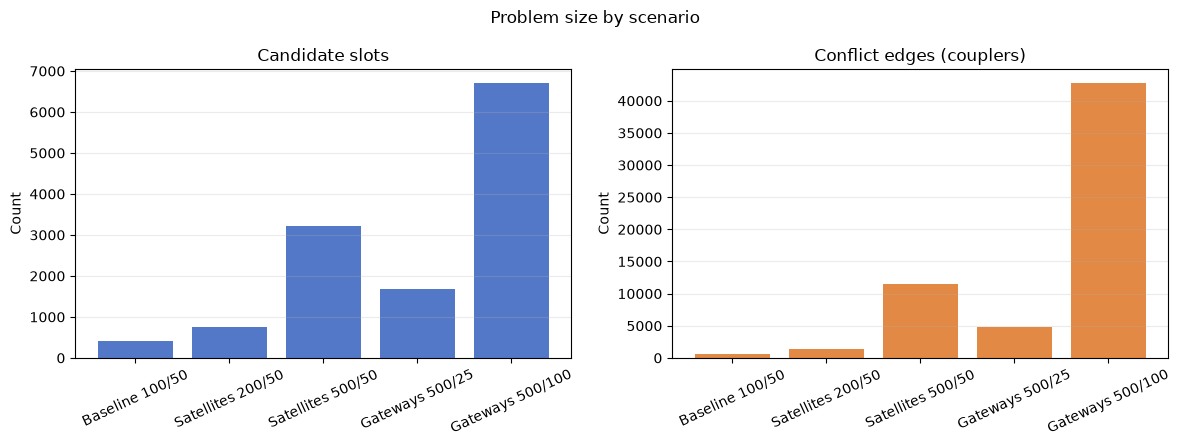

In [4]:
# Figure 1: growth in candidate slots and conflict edges.
labels = comparison["Scenario"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(labels, comparison["Candidate slots"], color="#5478c8")
axes[0].set_title("Candidate slots")
axes[0].set_ylabel("Count")
axes[1].bar(labels, comparison["Conflict edges"], color="#e28a45")
axes[1].set_title("Conflict edges (couplers)")
axes[1].set_ylabel("Count")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Problem size by scenario")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_1_problem_size.png", dpi=180, bbox_inches="tight")
plt.show()


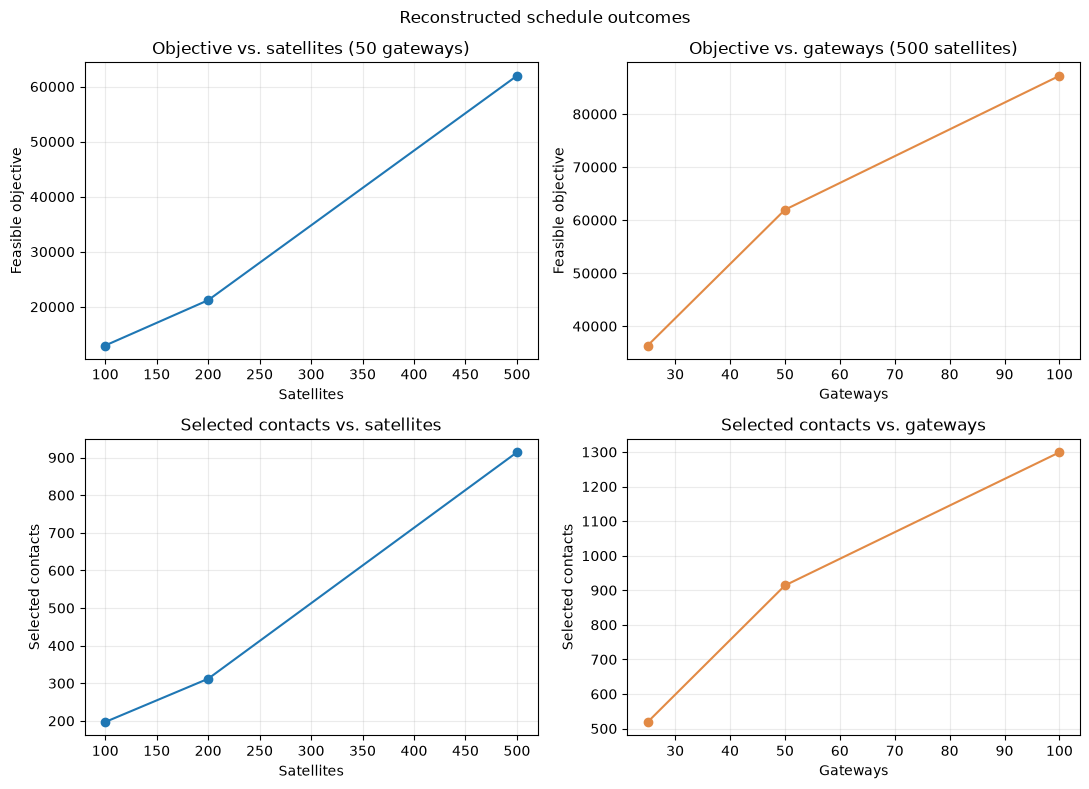

In [5]:
# Figure 2: schedule outcomes as satellite and gateway counts change.
satellite_runs = comparison[comparison["Gateways"] == 50].sort_values("Satellites")
gateway_runs = comparison[comparison["Satellites"] == 500].sort_values("Gateways")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(satellite_runs["Satellites"], satellite_runs["Feasible objective"], marker="o")
axes[0, 0].set(title="Objective vs. satellites (50 gateways)", xlabel="Satellites", ylabel="Feasible objective")
axes[0, 1].plot(gateway_runs["Gateways"], gateway_runs["Feasible objective"], marker="o", color="#e28a45")
axes[0, 1].set(title="Objective vs. gateways (500 satellites)", xlabel="Gateways", ylabel="Feasible objective")
axes[1, 0].plot(satellite_runs["Satellites"], satellite_runs["Selected contacts"], marker="o")
axes[1, 0].set(title="Selected contacts vs. satellites", xlabel="Satellites", ylabel="Selected contacts")
axes[1, 1].plot(gateway_runs["Gateways"], gateway_runs["Selected contacts"], marker="o", color="#e28a45")
axes[1, 1].set(title="Selected contacts vs. gateways", xlabel="Gateways", ylabel="Selected contacts")
for ax in axes.flat:
    ax.grid(alpha=0.25)
fig.suptitle("Reconstructed schedule outcomes")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_2_schedule_outcomes.png", dpi=180, bbox_inches="tight")
plt.show()


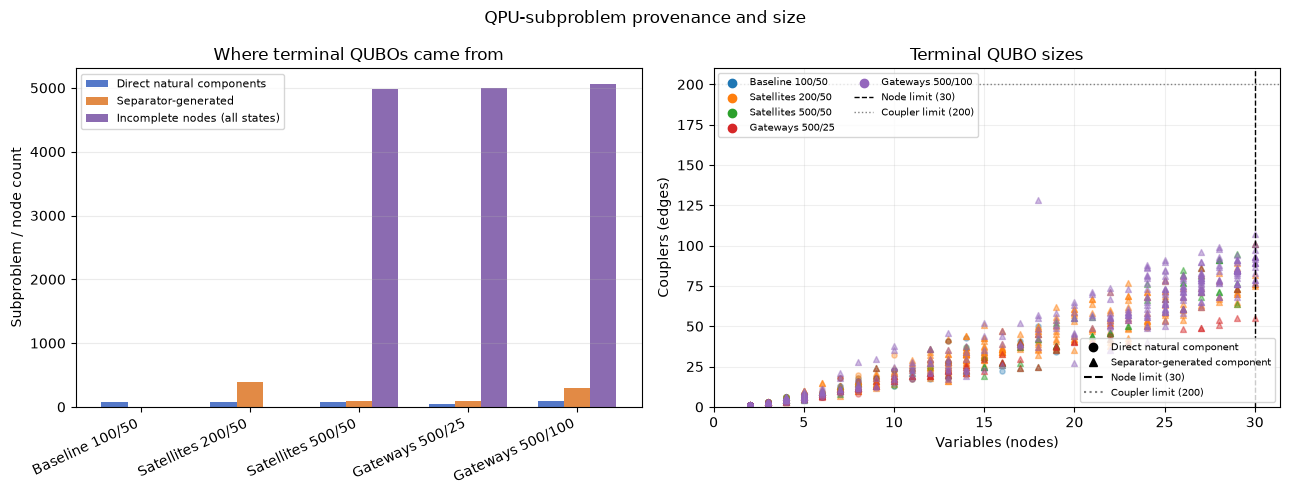

Saved table and figures to: C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\runs\mwis\experiment_comparison


In [6]:
# Figure 3: terminal provenance and terminal sizes against configured limits.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = range(len(comparison))
width = 0.24
axes[0].bar([i - width for i in x], comparison["Direct QUBOs"], width, label="Direct natural components", color="#5478c8")
axes[0].bar(x, comparison["Separator QUBOs"], width, label="Separator-generated", color="#e28a45")
axes[0].bar([i + width for i in x], comparison["Incomplete nodes"], width, label="Incomplete nodes (all states)", color="#8b6bb1")
axes[0].set_xticks(list(x), comparison["Scenario"], rotation=25, ha="right")
axes[0].set_ylabel("Subproblem / node count")
axes[0].set_title("Where terminal QUBOs came from")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.25)

colors = plt.get_cmap("tab10").colors
for index, data in enumerate(RUN_DATA):
    terminals = data["terminals"]
    direct = terminals[terminals["provenance"] == "terminal"]
    separator = terminals[terminals["provenance"] == "separator"]
    axes[1].scatter(direct["variables"], direct["couplers"], s=14, alpha=0.35, color=colors[index], marker="o")
    axes[1].scatter(separator["variables"], separator["couplers"], s=18, alpha=0.45, color=colors[index], marker="^")
    axes[1].scatter([], [], color=colors[index], marker="o", label=data["label"])

node_limit = RUN_DATA[0]["qpu_node_limit"]
coupler_limit = RUN_DATA[0]["qpu_coupler_limit"]
axes[1].axvline(node_limit, color="black", linestyle="--", linewidth=1, label=f"Node limit ({node_limit})")
axes[1].axhline(coupler_limit, color="gray", linestyle=":", linewidth=1, label=f"Coupler limit ({coupler_limit})")
axes[1].set(xlabel="Variables (nodes)", ylabel="Couplers (edges)", title="Terminal QUBO sizes")
axes[1].set_xlim(left=0)
axes[1].set_ylim(bottom=0)
axes[1].grid(alpha=0.2)
scenario_legend = axes[1].legend(fontsize=7, loc="upper left", ncol=2)
axes[1].add_artist(scenario_legend)
axes[1].legend(handles=[
    Line2D([], [], color="black", marker="o", linestyle="", label="Direct natural component"),
    Line2D([], [], color="black", marker="^", linestyle="", label="Separator-generated component"),
    Line2D([], [], color="black", linestyle="--", label=f"Node limit ({node_limit})"),
    Line2D([], [], color="gray", linestyle=":", label=f"Coupler limit ({coupler_limit})"),
], fontsize=7, loc="lower right")
fig.suptitle("QPU-subproblem provenance and size")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_3_qubo_provenance_and_size.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved table and figures to: {OUTPUT_DIR}")


## Experiment 4: QPU-size sensitivity

The three profiles below use the same frozen 500-satellite / 50-gateway input and current conflict graph. Only the terminal QUBO node and coupler limits change: 20/100, 30/200, and 50/350. The bounded LP reports tighten reporting bounds only; they do not change the annealed schedule or certify the integer optimum.

In [ ]:
EXP4_PROFILES = [
    {"run": "exp4_s500_g50_n20_c100", "label": "20 nodes / 100 couplers", "satellites": 500, "gateways": 50},
    {"run": "exp2_s500_g50", "label": "30 nodes / 200 couplers", "satellites": 500, "gateways": 50},
    {"run": "exp4_s500_g50_n50_c350", "label": "50 nodes / 350 couplers", "satellites": 500, "gateways": 50},
]

exp4_data = [load_scenario(spec) for spec in EXP4_PROFILES]
graph_signature = None
exp4_records = []
for data in exp4_data:
    signature = (set(data["nodes"]["slot_id"]), {tuple(sorted(edge)) for edge in data["edges"][ ["source", "target"] ].itertuples(index=False, name=None)})
    if graph_signature is None:
        graph_signature = signature
    elif signature != graph_signature:
        raise ValueError(f"Experiment 4 profiles do not use the same graph: {data['run']}")

    reconstructed = data["reconstructed"]
    mwis = data["mwis"]
    terminals = data["terminals"]
    selected = pd.read_csv(data["qubo_dir"] / "reconstructed_schedule.csv")
    selected_ids = set(selected["slot_id"])
    graph_edges = {tuple(sorted(edge)) for edge in data["edges"][ ["source", "target"] ].itertuples(index=False, name=None)}
    selected_conflicts = sum(1 for edge in graph_edges if edge[0] in selected_ids and edge[1] in selected_ids)
    objective = float(reconstructed["Total feasible objective"])
    if selected_conflicts or abs(float(selected["weight"].sum()) - objective) > 1e-5:
        raise ValueError(f"Reconstructed schedule failed validation: {data['run']}")

    lp_bound, lp_status = lp_refined_bound(data)
    pipeline_bound = float(reconstructed["MWIS producer conservative objective upper bound"])
    hybrid_bound = float(reconstructed.get("Hybrid conservative objective upper bound", pipeline_bound))
    exp4_records.append({
        "Profile": data["label"],
        "Run": data["run"],
        "QPU node limit": data["qpu_node_limit"],
        "QPU coupler limit": data["qpu_coupler_limit"],
        "Candidate slots": len(data["nodes"]),
        "Conflict edges": len(data["edges"]),
        "Natural components": int(float(mwis["Number of components (total)"])),
        "Direct QUBOs": data["direct_terminals"],
        "Separator QUBOs": data["separator_terminals"],
        "Incomplete components": int(float(mwis["Components with incomplete separator decomposition"])),
        "Incomplete nodes": int(float(mwis["Incomplete decomposition nodes (all states)"])),
        "Terminal QUBOs": len(terminals),
        "Max QUBO nodes": int(terminals["variables"].max()),
        "Max QUBO couplers": int(terminals["couplers"].max()),
        "Annealed used": int(float(reconstructed["Annealed terminal subgraphs used"])),
        "Selected contacts": int(float(reconstructed["Selected contacts"])),
        "Feasible objective": objective,
        "Pipeline upper bound": pipeline_bound,
        "Pipeline gap (%)": 100 * (pipeline_bound - objective) / pipeline_bound,
        "Hybrid upper bound": hybrid_bound,
        "Hybrid gap (%)": 100 * (hybrid_bound - objective) / hybrid_bound if hybrid_bound else None,
        "MILP attempted": int(float(reconstructed.get("MILP incomplete components attempted", 0))),
        "MILP proven optimal": int(float(reconstructed.get("MILP components proven optimal", 0))),
        "MILP unresolved": int(float(reconstructed.get("MILP components unresolved", 0))),
        "MILP solver seconds": float(reconstructed.get("MILP solver time (seconds)", 0.0)),
        "Triangle-LP seconds": float(reconstructed.get("Triangle-LP fallback solver time (seconds)", 0.0)),
        "LP-refined upper bound": lp_bound,
        "LP-refined gap (%)": 100 * (lp_bound - objective) / lp_bound if lp_bound else None,
        "LP check": lp_status,
        "Selected conflicts": selected_conflicts,
    })

exp4_comparison = pd.DataFrame(exp4_records)
exp4_comparison.to_csv(OUTPUT_DIR / "mwis_exp4_qpu_size_summary.csv", index=False, float_format="%.6f")
display(exp4_comparison.style.format({"Feasible objective": "{:,.3f}", "Pipeline upper bound": "{:,.3f}", "Hybrid upper bound": "{:,.3f}", "LP-refined upper bound": "{:,.3f}", "Pipeline gap (%)": "{:.3f}", "Hybrid gap (%)": "{:.3f}", "LP-refined gap (%)": "{:.3f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
x = range(len(exp4_comparison))
axes[0].bar([i - 0.18 for i in x], exp4_comparison["Direct QUBOs"], 0.36, label="Direct", color="#5478c8")
axes[0].bar([i + 0.18 for i in x], exp4_comparison["Separator QUBOs"], 0.36, label="Separator-generated", color="#e28a45")
axes[0].set(title="Terminal QUBOs by profile", ylabel="Count")
axes[0].legend(fontsize=8)

node_use = 100 * exp4_comparison["Max QUBO nodes"] / exp4_comparison["QPU node limit"]
coupler_use = 100 * exp4_comparison["Max QUBO couplers"] / exp4_comparison["QPU coupler limit"]
axes[1].bar([i - 0.18 for i in x], node_use, 0.36, label="Nodes used", color="#5478c8")
axes[1].bar([i + 0.18 for i in x], coupler_use, 0.36, label="Couplers used", color="#e28a45")
axes[1].axhline(100, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Largest terminal vs. configured limits", ylabel="Limit used (%)")
axes[1].legend(fontsize=8)

width = 0.19
axes[2].bar([i - 1.5 * width for i in x], exp4_comparison["Feasible objective"], width, label="Feasible objective", color="#5b9b77")
axes[2].bar([i - 0.5 * width for i in x], exp4_comparison["Hybrid upper bound"], width, label="MILP/LP hybrid bound", color="#d8903d")
axes[2].bar([i + 0.5 * width for i in x], exp4_comparison["LP-refined upper bound"], width, label="Triangle-LP bound", color="#8b6bb1")
axes[2].bar([i + 1.5 * width for i in x], exp4_comparison["Pipeline upper bound"], width, label="Original pipeline bound", color="#b7b7b7")
axes[2].set(title="Objective and upper bounds", ylabel="MWIS objective")
axes[2].legend(fontsize=7)

for ax in axes:
    ax.set_xticks(list(x), exp4_comparison["Profile"], rotation=25, ha="right")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Experiment 4: QPU-size sensitivity (same S500/G50 conflict graph)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_4_qpu_size_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved Experiment 4 table and figure to: {OUTPUT_DIR}")